# PROYECTO DE TESIS DE IA — CARTPOLE CON DDPG
## Entregable único: importancia de las variables y matriz de consistencia
**Fecha:** 30 de octubre de 2026  
**Alcance:** investigación del predictor de dinámica basado en datos de simulación del sistema CartPole controlado mediante DDPG. El entrenamiento de la política DDPG y el entrenamiento del predictor Ridge son procedimientos diferentes.

**Objetivo de esta entrega:** (1) justificar las variables del estudio y medir la importancia predictiva de características; (2) presentar la matriz de consistencia (problema, objetivos, hipótesis y variables).  
**Evidencia:** se incorpora la prueba exploratoria ya ejecutada, y se dejan celdas reproducibles para validación ampliada. No se atribuyen resultados a experimentos que aún no se hayan ejecutado.

## A. Importancia de las variables: definición y justificación
**Variable independiente (VI):** configuración de características del predictor: **BASE6** (6 variables originales) frente a **FISICA12** (6 originales + 6 derivadas de la física).  
**Variable dependiente (VD):** desempeño predictivo fuera de entrenamiento, medido por **RMSE** del cambio de velocidad lineal (Δv) y del cambio de velocidad angular (Δω).  
**Variables de control:** algoritmo Ridge, hiperparámetro α=1, partición 70/30 por episodio, mismas observaciones y condiciones de evaluación para ambos modelos.

**Relevancia para la IA:** permite comprobar si introducir conocimiento físico como representación de entrada mejora la generalización del modelo de regresión supervisada. Las 45 columnas del CSV **no** son 45 predictores obligatorios; algunas contienen identificadores, estados posteriores y variables auxiliares. **Las dos salidas Δv y Δω no se emplean como características.**

**Aclaración:** la política DDPG usa estados para elegir acciones y optimiza recompensa acumulada. El experimento de este notebook evalúa un **predictor Ridge de dinámica** con registros generados durante simulación/control de CartPole, no la calidad de la política DDPG.

### A1. Características de entrada y razón física
| Grupo | Características | Justificación |
|---|---|---|
| BASE6 | `x_pre`, `v_pre`, `theta_pre`, `omega_pre`, `u_control_N`, `fuerza_perturbacion_N` | Estado previo y fuerzas disponibles al decidir la acción |
| 6 físicas adicionales | `sin_theta_pre`, `cos_theta_pre`, `energia_potencial_pre_J`, `energia_cinetica_angular_pre_J`, `energia_cinetica_carro_pre_J`, `margen_riel_pre_m` | Periodicidad angular, energía mecánica y proximidad al límite del riel |
| Objetivos (no predictores) | `delta_v_m_s`, `delta_omega_rad_s` | Cambios entre instante previo y posterior |

**Advertencias:** las fórmulas y parámetros del sistema deben coincidir con el simulador. Las energías se calculan a partir de estados conocidos antes de la acción. La importancia por permutación mide contribución predictiva en un conjunto dado, **no causalidad**; con variables correlacionadas puede repartir o subestimar su importancia individual.

**FE_Física15:** conjunto mencionado en trabajos anteriores; no se evalúa aquí porque no se dispone en este notebook de la definición verificable de sus 15 columnas. Evitamos confundirlo con FISICA12.

### A2. Evidencia preliminar ya observada — 20 episodios, una partición
| Salida | RMSE BASE6 | RMSE FISICA12 | Reducción relativa del RMSE |
|---|---:|---:|---:|
| Δv (m/s) | 0.002123 | 0.002098 | **1.18 %** |
| Δω (rad/s) | 0.051084 | 0.037565 | **26.46 %** |

**Interpretación:** en esta partición exploratoria, FISICA12 redujo el RMSE en ambos objetivos; el efecto fue mayor en Δω. **No constituye aún demostración estadística ni garantiza generalización.** Se necesita validar repetidamente con episodios independientes, analizar variabilidad y mantener un conjunto de prueba final sin utilizar para selección de características.

*Nota:* los porcentajes provienen de las salidas mostradas de la ejecución anterior (los RMSE tabulados están redondeados).

## B. Preparar los datos reales en Colab
Este bloque busca el CSV en rutas comunes de Colab y Google Drive, incluida una búsqueda por nombre dentro de «Mi unidad». No escribe ni modifica el CSV. Si tu archivo tiene otro nombre, edita `NOMBRE_CSV`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/CartPole_Tesis/datos')
except ImportError:
    DATA_DIR = Path('datos')

NOMBRE_CSV = 'caracteristicas_paso_a_paso.csv'
carpetas = [DATA_DIR, Path('/content'), Path('/content/drive/MyDrive/CartPole_Tesis'), Path('datos')]
candidatos = [p / NOMBRE_CSV for p in carpetas]
CSV_PATH = next((p for p in candidatos if p.is_file()), None)
if CSV_PATH is None and Path('/content/drive/MyDrive').exists():
    hallados = list(Path('/content/drive/MyDrive').rglob(NOMBRE_CSV))
    CSV_PATH = hallados[0] if hallados else None
if CSV_PATH is None:
    raise FileNotFoundError('No se encontró el CSV. Revisa el nombre o súbelo al panel Archivos de Colab.')

df = pd.read_csv(CSV_PATH, low_memory=False)
print('Archivo:', CSV_PATH)
print('Dimensiones:', df.shape)
print('Episodios:', df['id_ensayo'].nunique() if 'id_ensayo' in df else 'No disponible')

Mounted at /content/drive
Archivo: /content/drive/MyDrive/CartPole_Tesis/caracteristicas_paso_a_paso.csv
Dimensiones: (600000, 45)
Episodios: 100


### B1. Construcción de las características y las dos variables objetivo
El bloque siguiente reproduce las seis fórmulas del notebook trabajado. Comprueba `m`, `M`, `l`, `g` y `X_RAIL` con el modelo real de simulación.

In [2]:
required = ['id_ensayo', 'x_pre', 'v_pre', 'theta_pre', 'omega_pre',
            'v', 'omega', 'u_control_N', 'fuerza_perturbacion_N']
missing = sorted(set(required) - set(df.columns))
if missing:
    raise KeyError(f'Faltan columnas requeridas: {missing}')

# Parámetros documentados en la captura del notebook original; verificar con el simulador.
m, M, l, L, g = 0.1, 1.0, 0.5, 1.0, 9.81
I = m*l**2/12
Jp = I + m*l**2
X_RAIL = 2.4

df['delta_v_m_s'] = df['v'] - df['v_pre']
df['delta_omega_rad_s'] = df['omega'] - df['omega_pre']
df['sin_theta_pre'] = np.sin(df['theta_pre'])
df['cos_theta_pre'] = np.cos(df['theta_pre'])
df['energia_potencial_pre_J'] = m*g*l*(np.cos(df['theta_pre'])-1)
df['energia_cinetica_angular_pre_J'] = 0.5*Jp*df['omega_pre']**2
df['energia_cinetica_carro_pre_J'] = 0.5*M*df['v_pre']**2
df['margen_riel_pre_m'] = X_RAIL-np.abs(df['x_pre'])

BASE6 = ['x_pre', 'v_pre', 'theta_pre', 'omega_pre', 'u_control_N', 'fuerza_perturbacion_N']
FISICA12 = BASE6 + ['sin_theta_pre', 'cos_theta_pre', 'energia_potencial_pre_J',
                     'energia_cinetica_angular_pre_J', 'energia_cinetica_carro_pre_J', 'margen_riel_pre_m']
TARGETS = ['delta_v_m_s', 'delta_omega_rad_s']

print('Predictores BASE6:',len(BASE6),'| FISICA12:',len(FISICA12))
print('Objetivos:', TARGETS)

Predictores BASE6: 6 | FISICA12: 12
Objetivos: ['delta_v_m_s', 'delta_omega_rad_s']


## C. Validación ampliada de la importancia de la ingeniería de características
Se evalúan **hasta 100 episodios**, cinco particiones repetidas 70/30 **agrupadas por episodio** y dos modelos idénticos excepto por sus entradas. Se muestra media y dispersión del RMSE y reducción porcentual. **Las particiones repetidas no sustituyen un test final independiente.**

In [3]:
cols = list(dict.fromkeys(FISICA12 + TARGETS + ['id_ensayo']))
datos = df[cols].replace([np.inf, -np.inf], np.nan).dropna().copy()
episodios = datos['id_ensayo'].drop_duplicates()
if len(episodios) < 10:
    raise ValueError('Se necesitan más episodios para esta validación.')
episodios = episodios.iloc[:100]
datos = datos[datos['id_ensayo'].isin(episodios)].copy()
print('Filas usadas:', len(datos), '| episodios:', datos['id_ensayo'].nunique())

splitter = GroupShuffleSplit(n_splits=5, train_size=0.70, random_state=42)
filas = []
for rep, (i_train, i_test) in enumerate(splitter.split(datos, groups=datos['id_ensayo']), start=1):
    train, test = datos.iloc[i_train], datos.iloc[i_test]
    for objetivo in TARGETS:
        for etiqueta, vars_ in [('BASE6', BASE6), ('FISICA12', FISICA12)]:
            model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
            model.fit(train[vars_], train[objetivo])
            pred = model.predict(test[vars_])
            rmse = np.sqrt(mean_squared_error(test[objetivo], pred))
            filas.append({'repeticion':rep, 'objetivo':objetivo, 'modelo':etiqueta, 'RMSE':rmse})
resultados = pd.DataFrame(filas)
resumen = resultados.groupby(['objetivo','modelo'])['RMSE'].agg(['mean','std']).reset_index()
print('Resumen por objetivo y modelo (RMSE):')
print(resumen.to_string(index=False))

wide = resultados.pivot(index=['repeticion','objetivo'], columns='modelo', values='RMSE').reset_index()
wide['mejora_pct'] = 100*(wide['BASE6']-wide['FISICA12'])/wide['BASE6']
print('\nReducción del RMSE (%) por partición:')
print(wide[['repeticion','objetivo','mejora_pct']].to_string(index=False))
print('\nResumen de mejoras (%):')
print(wide.groupby('objetivo')['mejora_pct'].agg(['mean','std','min','max']).to_string())

Filas usadas: 600000 | episodios: 100
Resumen por objetivo y modelo (RMSE):
         objetivo   modelo     mean      std
delta_omega_rad_s    BASE6 0.051714 0.001137
delta_omega_rad_s FISICA12 0.037921 0.001084
      delta_v_m_s    BASE6 0.002160 0.000036
      delta_v_m_s FISICA12 0.002132 0.000030

Reducción del RMSE (%) por partición:
 repeticion          objetivo  mejora_pct
          1 delta_omega_rad_s   26.909509
          1       delta_v_m_s    1.390292
          2 delta_omega_rad_s   27.204521
          2       delta_v_m_s    1.569313
          3 delta_omega_rad_s   26.028397
          3       delta_v_m_s    0.840167
          4 delta_omega_rad_s   27.207982
          4       delta_v_m_s    1.562928
          5 delta_omega_rad_s   26.044221
          5       delta_v_m_s    1.139169

Resumen de mejoras (%):
                        mean       std        min        max
objetivo                                                    
delta_omega_rad_s  26.678926  0.599032  26.028397  

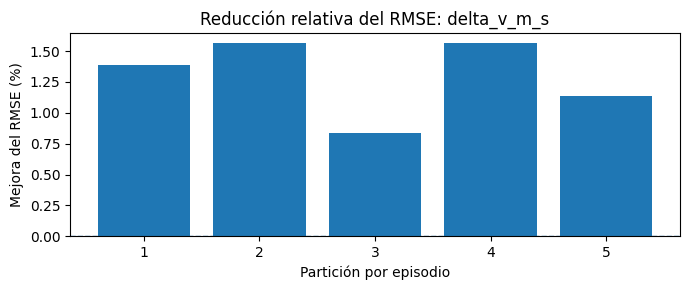

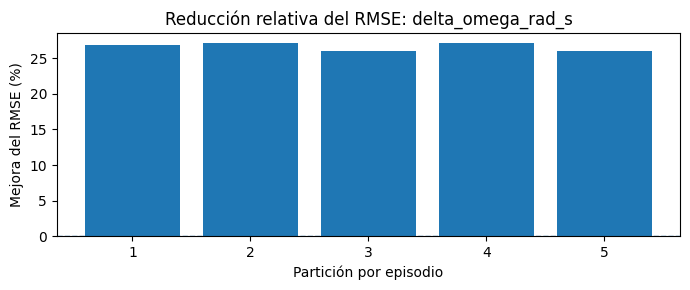

In [4]:
for objetivo in TARGETS:
    sel = wide[wide['objetivo']==objetivo]
    fig, ax = plt.subplots(figsize=(7,3))
    ax.bar(sel['repeticion'].astype(str), sel['mejora_pct'])
    ax.axhline(0, linestyle='--', linewidth=1)
    ax.set_title('Reducción relativa del RMSE: ' + objetivo)
    ax.set_xlabel('Partición por episodio')
    ax.set_ylabel('Mejora del RMSE (%)')
    plt.tight_layout()
    plt.show()

### C1. Importancia predictiva por permutación
Mide cuánto aumenta el RMSE cuando se altera una entrada en episodios de prueba. Un aumento positivo más alto sugiere mayor relevancia para ese predictor y ese objetivo. Es un análisis exploratorio con una partición, y el ranking puede cambiar por correlación entre características.

In [5]:
# Partición fija solo para un análisis exploratorio de importancia.
train_i, test_i = next(GroupShuffleSplit(n_splits=1,train_size=0.7,random_state=2026).split(datos,groups=datos['id_ensayo']))
tr, te = datos.iloc[train_i], datos.iloc[test_i]
rng = np.random.default_rng(2026)
importancias=[]
for objetivo in TARGETS:
    mod = make_pipeline(StandardScaler(),Ridge(alpha=1.0))
    mod.fit(tr[FISICA12],tr[objetivo])
    base_rmse=np.sqrt(mean_squared_error(te[objetivo],mod.predict(te[FISICA12])))
    X=te[FISICA12].copy()
    for col in FISICA12:
        cambios=[]
        for _ in range(3):
            Xp=X.copy()
            Xp[col]=rng.permutation(Xp[col].to_numpy())
            r=np.sqrt(mean_squared_error(te[objetivo],mod.predict(Xp)))
            cambios.append(r-base_rmse)
        importancias.append({'objetivo':objetivo,'caracteristica':col,'aumento_RMSE':np.mean(cambios)})
imp=pd.DataFrame(importancias)
for objetivo in TARGETS:
    print('\n', objetivo)
    print(imp[imp.objetivo==objetivo].sort_values('aumento_RMSE',ascending=False).to_string(index=False))


 delta_v_m_s
   objetivo                 caracteristica  aumento_RMSE
delta_v_m_s                    u_control_N  6.969284e-02
delta_v_m_s          fuerza_perturbacion_N  3.609688e-03
delta_v_m_s                      theta_pre  1.130059e-03
delta_v_m_s                          v_pre  1.843161e-04
delta_v_m_s                  sin_theta_pre  1.399300e-04
delta_v_m_s                      omega_pre  5.242033e-05
delta_v_m_s                          x_pre  4.751804e-05
delta_v_m_s energia_cinetica_angular_pre_J  5.868788e-06
delta_v_m_s              margen_riel_pre_m  1.643613e-06
delta_v_m_s                  cos_theta_pre -5.321139e-07
delta_v_m_s        energia_potencial_pre_J -5.690189e-07
delta_v_m_s   energia_cinetica_carro_pre_J -6.011896e-07

 delta_omega_rad_s
         objetivo                 caracteristica  aumento_RMSE
delta_omega_rad_s                    u_control_N      0.055869
delta_omega_rad_s                  sin_theta_pre      0.046177
delta_omega_rad_s                   

## D. Matriz de consistencia — Proyecto de tesis (IA)
**Título de trabajo para este estudio:** *Evaluación de la ingeniería de características físicas en la predicción de la dinámica de un sistema CartPole a partir de datos de simulación con control DDPG.*  
**Delimitación:** esta matriz documenta el experimento predictivo Ridge dentro del proyecto DDPG/CartPole; **no sustituye** los objetivos globales del estudio de control DDPG–LQR/DDPG–ISMC si estos forman parte de la tesis completa.

| Nivel | Problema de investigación | Objetivo | Hipótesis | Variables / indicadores |
|---|---|---|---|---|
| General | ¿En qué medida la ingeniería de características físicas mejora la predicción de la dinámica CartPole frente a las características originales? | Evaluar el efecto de incluir características físicas derivadas sobre el error de predicción de la dinámica CartPole. | HG: FISICA12 obtiene menor RMSE promedio que BASE6 en episodios no usados para entrenamiento. | VI: conjunto BASE6 / FISICA12. VD: RMSE de Δv y Δω. |
| Específico 1 | ¿Cómo cambia la predicción de Δv al agregar características físicas? | Comparar el RMSE de Δv entre BASE6 y FISICA12. | HE1: FISICA12 reduce el RMSE de Δv frente a BASE6. | Indicador: reducción % del RMSE de Δv. |
| Específico 2 | ¿Cómo cambia la predicción de Δω al agregar características físicas? | Comparar el RMSE de Δω entre BASE6 y FISICA12. | HE2: FISICA12 reduce el RMSE de Δω frente a BASE6. | Indicador: reducción % del RMSE de Δω. |
| Específico 3 | ¿Qué características contribuyen más a la predicción fuera de entrenamiento? | Estimar y comparar la importancia por permutación de las características en ambos objetivos. | HE3: las características no aportan por igual al RMSE; al menos algunas presentan importancia predictiva positiva. | Indicador: incremento de RMSE al permutar cada predictor. |

**Diseño metodológico:** cuantitativo, experimental computacional comparativo; fuente secundaria: registros de simulación; unidad de agrupación: episodio (`id_ensayo`); evaluación 70 % entrenamiento / 30 % prueba por episodio; modelo Ridge con normalización aprendida solo en entrenamiento; análisis descriptivo de cinco particiones. Se requiere validación final para afirmar robustez.

### D1. Matriz de consistencia
La matriz se presenta con encabezados azul oscuro, fondo blanco, texto negro, bordes definidos y desplazamiento horizontal para una lectura completa en Google Colab.

In [6]:
from IPython.display import display, HTML
matriz = pd.DataFrame([
    {'Nivel':'General','Problema':'¿En qué medida la ingeniería de características físicas mejora la predicción de la dinámica CartPole?', 'Objetivo':'Evaluar el efecto de FISICA12 frente a BASE6 sobre el error de predicción.', 'Hipótesis':'HG: FISICA12 tiene menor RMSE promedio que BASE6.', 'VI':'Conjunto de características BASE6/FISICA12','VD/Indicador':'RMSE de Δv y Δω'},
    {'Nivel':'Específico 1','Problema':'¿Mejora la predicción de Δv?', 'Objetivo':'Comparar el RMSE de Δv.', 'Hipótesis':'HE1: FISICA12 reduce el RMSE de Δv.', 'VI':'BASE6/FISICA12','VD/Indicador':'RMSE y reducción % de Δv'},
    {'Nivel':'Específico 2','Problema':'¿Mejora la predicción de Δω?', 'Objetivo':'Comparar el RMSE de Δω.', 'Hipótesis':'HE2: FISICA12 reduce el RMSE de Δω.', 'VI':'BASE6/FISICA12','VD/Indicador':'RMSE y reducción % de Δω'},
    {'Nivel':'Específico 3','Problema':'¿Qué predictores contribuyen más?', 'Objetivo':'Estimar importancia predictiva por permutación.', 'Hipótesis':'HE3: algunas características presentan importancia positiva.', 'VI':'Características individuales','VD/Indicador':'Aumento de RMSE tras permutación'}
])
# Visualización académica con encabezados azul oscuro y celdas blancas.
# CSS incorporado en cada celda para respetar los colores incluso en el tema oscuro de Colab.
from html import escape
from IPython.display import HTML, display

columns = list(matriz.columns)
pretty = {
    'Nivel': 'Nivel',
    'Problema': 'Problema de investigación',
    'Objetivo': 'Objetivo de investigación',
    'Hipótesis': 'Hipótesis',
    'VI': 'Variable independiente / factor',
    'VD/Indicador': 'Variable dependiente / indicador'
}

header_cells = '<th style="background:#214f78!important;color:white!important;border:2px solid #24303a;padding:14px 12px;text-align:center;vertical-align:middle;">N.º</th>'
for col in columns:
    header_cells += (f'<th style="background:#214f78!important;color:#ffffff!important;'
                     f'border:2px solid #24303a;padding:14px 12px;'
                     f'text-align:center;vertical-align:middle;">{escape(pretty.get(col,col))}</th>')

rows = []
for index, (_, r) in enumerate(matriz.iterrows(), 1):
    row = (f'<td style="background:#214f78!important;color:#ffffff!important;'
           f'border:2px solid #24303a;text-align:center;vertical-align:middle;'
           f'font-weight:bold;padding:12px;">{index}</td>')
    for col in columns:
        row += (f'<td style="background:#ffffff!important;color:#111111!important;'
                f'border:2px solid #303030;padding:15px 13px;vertical-align:top;'
                f'white-space:normal;overflow-wrap:break-word;line-height:1.48;">'
                f'{escape(str(r[col]))}</td>')
    rows.append(f'<tr>{row}</tr>')

html_tabla = f"""
<div style="background:#ffffff!important;color:#111111!important;padding:16px 16px 20px;
            font-family:Arial,Helvetica,sans-serif;border:1px solid #d5d5d5;">
  <h2 style="color:#183b5b!important;font-size:21px;margin:5px 0 4px;">Matriz de consistencia</h2>
  <p style="color:#333!important;margin:0 0 16px;font-size:13px;">
    Ingeniería de características físicas para la predicción de la dinámica del CartPole
  </p>
  <div style="overflow-x:auto;max-width:100%;background:#fff!important;">
    <table style="min-width:1550px;width:100%;border-collapse:collapse;table-layout:fixed;
                  background:white!important;color:#111!important;font-size:13px;">
      <colgroup>
        <col style="width:4%"><col style="width:9%"><col style="width:20%">
        <col style="width:20%"><col style="width:18%"><col style="width:15%"><col style="width:14%">
      </colgroup>
      <thead><tr>{header_cells}</tr></thead>
      <tbody>{''.join(rows)}</tbody>
    </table>
  </div>
  <p style="font-size:12px;color:#333!important;margin:12px 0 0;">
    VI: variable independiente · VD: variable dependiente · RMSE: raíz del error cuadrático medio.
  </p>
</div>
"""
display(HTML(html_tabla))
matriz.to_csv('matriz_consistencia_cartpole.csv',index=False,encoding='utf-8-sig')
print('Generado: matriz_consistencia_cartpole.csv')


N.º,Nivel,Problema de investigación,Objetivo de investigación,Hipótesis,Variable independiente / factor,Variable dependiente / indicador
1,General,¿En qué medida la ingeniería de características físicas mejora la predicción de la dinámica CartPole?,Evaluar el efecto de FISICA12 frente a BASE6 sobre el error de predicción.,HG: FISICA12 tiene menor RMSE promedio que BASE6.,Conjunto de características BASE6/FISICA12,RMSE de Δv y Δω
2,Específico 1,¿Mejora la predicción de Δv?,Comparar el RMSE de Δv.,HE1: FISICA12 reduce el RMSE de Δv.,BASE6/FISICA12,RMSE y reducción % de Δv
3,Específico 2,¿Mejora la predicción de Δω?,Comparar el RMSE de Δω.,HE2: FISICA12 reduce el RMSE de Δω.,BASE6/FISICA12,RMSE y reducción % de Δω
4,Específico 3,¿Qué predictores contribuyen más?,Estimar importancia predictiva por permutación.,HE3: algunas características presentan importancia positiva.,Características individuales,Aumento de RMSE tras permutación


Generado: matriz_consistencia_cartpole.csv


## E. Conclusiones
En la exploración inicial de datos de simulación CartPole, el predictor Ridge con seis características originales (BASE6) se comparó con una versión ampliada con seis características físicas (FISICA12). Para la partición preliminar evaluada, el RMSE disminuyó **1.18 %** en la predicción del cambio de velocidad del carro y **26.46 %** en el cambio de velocidad angular del péndulo. Estos hallazgos respaldan **de forma preliminar** la pertinencia de investigar ingeniería de características físicas como variable independiente y error predictivo como variable dependiente. La matriz de consistencia formaliza preguntas, objetivos e hipótesis verificables; la validación por episodios y el análisis de importancia permiten comprobar si la mejora se mantiene. No se infiere causalidad ni significación estadística a partir de una única partición.

**Para entregar:** ejecutar las celdas en orden, incorporar la salida de validación ampliada si concluye correctamente y subir **este único `.ipynb`** a la rama de GitHub indicada por el curso. El CSV de gran tamaño puede quedar en Drive, fuera del repositorio.